# Lab Assignment 1 - Convolutional Neural Networks

This notebook contains the **Part B** assignment tasks.
Use the lab session notebook for Part A demos and architecture notes (A9) if needed. Implement your solutions in the code cells below.

# Part B Assignment

Use this section to develop the main tasks and, optionally, the two challenges. Each task has a broad description followed by one consolidated answer code cell. You may design different interfaces, experiments and plots. Justify your choices and follow the accompanying assignment description for submission requirements.

## Task 1. Study and Prepare the Data

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF
from pathlib import Path
# cpu as a fallback
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: mps


In [9]:
from IPython.display import display
from torchvision.datasets.utils import download_and_extract_archive
DATA_ROOT = Path("data")
try:
  database = datasets.CIFAR10(DATA_ROOT, train=True, download=False)
except:
  # faster than download with datasets
  download_and_extract_archive(
      "https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz",
      download_root=str(DATA_ROOT),
      filename="cifar-10-python.tar.gz",
      md5="c58f30108f718f92721af3b95e74349a",
  )
  database = datasets.CIFAR10(DATA_ROOT, train=True, download=False)

labels = np.asarray(database.targets)
class_names = database.classes

print("Images:", database.data.shape, database.data.dtype)
print("Pixel range:", database.data.min(), database.data.max())
display(
    pd.DataFrame(
        {
            "class": class_names,
            "count": np.bincount(labels, minlength=10),
        }
    )
)

Images: (50000, 32, 32, 3) uint8
Pixel range: 0 255


,class,count
0,airplane,5000
1,automobile,5000
2,bird,5000
3,cat,5000
4,deer,5000
5,dog,5000
6,frog,5000
7,horse,5000
8,ship,5000
9,truck,5000


**Q: What does an example represent, and how are the classes distributed?**

An example is a 32x32 RGB image with a single class label from the ten CIFAR-10 categories. The official training set has 50,000 images with pixel values in [0, 255], and the classes are balanced (5,000 images per class).


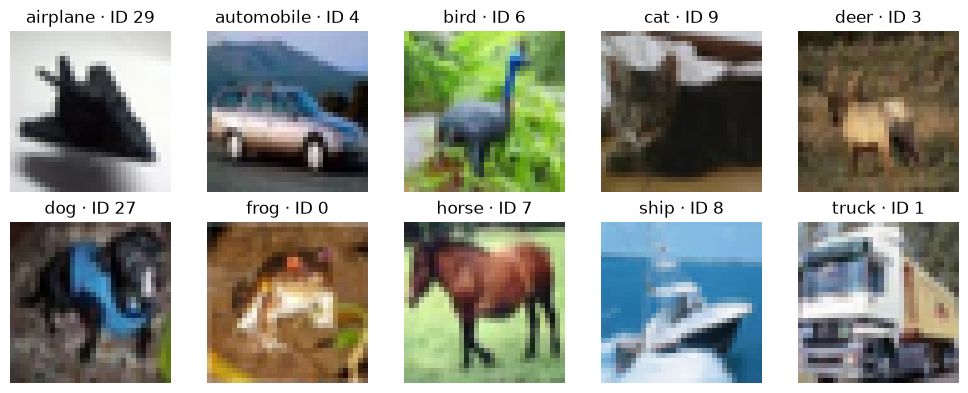

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for target, ax in enumerate(axes.flat):
    image_id = int(np.flatnonzero(labels == target)[0])
    ax.imshow(database.data[image_id])
    ax.set_title(f"{class_names[target]} · ID {image_id}")
    ax.axis("off")
fig.tight_layout()
plt.show()

In [11]:

from sklearn.model_selection import train_test_split
SEED = 2223

train_ids, val_ids = train_test_split(
    np.arange(len(database)),
    test_size=0.1,
    stratify=labels,
    random_state=SEED,
)
train_ids, val_ids = np.sort(train_ids), np.sort(val_ids)
assert set(train_ids).isdisjoint(val_ids)

print("Training / validation:", len(train_ids), len(val_ids))


Training / validation: 45000 5000


In [12]:
test_database = datasets.CIFAR10(DATA_ROOT, train=False, download=False)
test_ids = np.arange(len(test_database))
print("Test:", len(test_ids))
assert set(train_ids).isdisjoint(val_ids)

Test: 10000


In [13]:
from tqdm import tqdm

channel_sum = np.zeros(3)
channel_square_sum = np.zeros(3)
pixel_count = 0

# we process images in a batch of 256
for start in tqdm(range(0, len(train_ids), 256)):
    pixels = database.data[train_ids[start : start + 256]].astype(np.float64) / 255
    channel_sum += pixels.sum(axis=(0, 1, 2)) # sum across samples in a batch, image heights, image widths
    channel_square_sum += np.square(pixels).sum(axis=(0, 1, 2))
    pixel_count += np.prod(pixels.shape[:3])

mean = channel_sum / pixel_count
std = np.sqrt(np.maximum(channel_square_sum / pixel_count - mean**2, 1e-12))
stats = {"mean": mean.tolist(), "std": std.tolist()}
display(pd.DataFrame(stats, index=["red", "green", "blue"]))

100%|████████████████████████████████████████████████████████████████████| 176/176 [00:00<00:00, 685.37it/s]


,mean,std
red,0.491318,0.247001
green,0.482180,0.243401
blue,0.446389,0.261544


In [14]:
class RawImages(Dataset):
    def __init__(self, dataset, ids):
        self.dataset = dataset
        self.ids = list(map(int, ids))

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):  # ty: ignore[lost-keyword-for-regular-parameter]
        image_id = self.ids[idx]
        image, target = self.dataset[image_id]
        return TF.to_tensor(image), int(target), image_id

In [15]:
def prepare_inputs(raw, stats):
    mean = raw.new_tensor(stats["mean"])[None, :, None, None]
    std = raw.new_tensor(stats["std"])[None, :, None, None]
    return (raw - mean) / std

**Q: Which preprocessing steps are needed for the two architectures?**

Both AlexNet and ResNet use the CIFAR-10 adaptations from Part A9, so they take native 3x32x32 inputs. We apply the same preprocessing to both: convert uint8 images to float tensors in [0, 1], then normalize each channel with the mean and standard deviation computed on the training split only.


**Q: How is the dataset preprocessed and splitted?**

We split the official training set into 45,000 training and 5,000 validation images (stratified 90/10, seed 2223). The official 10,000-image test set is held out for final evaluation. Images are converted to [0, 1] tensors and normalized with training-set mean/std.

In [42]:
# This class has been created here as it is necessary for the loader for task 4.
# It will be relevant for task 4


class AugmentedImages(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

        # crop adds 4 pixels of padding around the image and then selects a 32x32 cell
        self.transform = transforms.Compose([
            transforms.RandomCrop(
                size=32,
                padding=4,
                padding_mode="reflect",
            ),
            transforms.RandomHorizontalFlip(p=0.5), # horizontal flip applies a mirror of the image left to right with probability p
        ])

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        # apply the transformation
        image, target, image_id = self.base_dataset[index]
        augmented_image = self.transform(image)
        return augmented_image, target, image_id


In [43]:
import random
from dataclasses import asdict, dataclass, replace


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


@dataclass
class Run:
    name: str
    model: str = "AlexNet"
    group: str = "baseline"
    seed: int = 2223
    epochs: int = 20
    batch_size: int = 64
    lr: float = 0.01
    momentum: float = 0.9
    l2: float = 0.0
    dropout: float = 0.5
    width_mult: float = 1.0
    augmentation: bool = False
    smoke: bool = False

    def get_smoke(self, epochs: int = 1) -> "Run":
        return replace(self, smoke=True, epochs=epochs)


@dataclass
class Loaders:
    train: DataLoader
    train_eval: DataLoader
    val: DataLoader
    test: DataLoader | None = None


def make_loaders(
    run: Run,
    train_subset,
    val_subset,
    *,
    include_test=False,
) -> Loaders:

    generator = torch.Generator().manual_seed(run.seed)

    # Clean training images, also used for training-set evaluation.
    clean_train = RawImages(database, train_subset)

    # Apply augmentation only when the run requests it.
    training_data = (
        AugmentedImages(clean_train)
        if run.augmentation
        else clean_train
    )

    def make_loader(dataset, *, shuffle=False):
        return DataLoader(
            dataset,
            batch_size=run.batch_size,
            shuffle=shuffle,
            num_workers=0,
            pin_memory=device.type == "cuda",
            generator=generator if shuffle else None,
        )

    return Loaders(
        train=make_loader(training_data, shuffle=True),
        train_eval=make_loader(clean_train),
        val=make_loader(RawImages(database, val_subset)),
        test=(
            make_loader(RawImages(test_database, test_ids))
            if include_test
            else None
        ),
    )



inspect_run = Run(name="inspect", seed=SEED, batch_size=128, epochs=1)
set_seed(inspect_run.seed)
loaders = make_loaders(inspect_run, train_ids, val_ids, include_test=True)
print(
    f"{inspect_run.name}: "
    f"{len(loaders.train)} train / {len(loaders.val)} val / {len(loaders.test)} test batches"
)


inspect: 352 train / 40 val / 79 test batches


**Q: How to control the randomness in the experiment?**

We fix the train/validation split with `SEED = 2223`, seed Python/NumPy/PyTorch through `set_seed`, and rebuild each DataLoader shuffle generator from `Run.seed`. That keeps the partition and batch order stable across runs.


## Task 2. Implement and Compare the Models
Implement and train AlexNet and ResNet using PyTorch layers, starting from the architectures and CIFAR-10 adaptations discussed in A9. Explain any differences from the original designs, observe feature shapes and compare the models under a justified compute budget. Do not use pretrained weights or readily-available model constructors.

Choose your optimizer, training schedule, checkpoint rule and evaluation metrics. Justify your choices. Report numerical performance, parameter counts, training cost, number of trained samples and relevant limitations. You are free to define different model construction, training and evaluation rather than following part A.

In [18]:
# AlexNet
class AlexNet(nn.Module):
    def __init__(self, dropout: float = 0.5, width_mult: float = 1.0):
        super().__init__()

        def width(channels: int) -> int:
            return max(8, int(round(channels * width_mult)))

        c1, c2, c3, c4, c5 = map(width, (64, 192, 384, 256, 256))
        fc1, fc2 = map(width, (1024, 512))
        flat = c5 * 4 * 4

        self.network = nn.Sequential(
            nn.Conv2d(3, c1, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(c1, c2, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(c2, c3, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(c3, c4, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(c4, c5, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(flat, fc1),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(fc1, fc2),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(fc2, 10),
        )

    def forward(self, x):
        return self.network(x)


AlexNet()(torch.randn(2, 3, 32, 32)).shape


torch.Size([2, 10])

In [19]:
# BasicBlock

class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=3,
                padding=1,
                stride=stride,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=out_channels,
                out_channels=out_channels,
                kernel_size=3,
                padding=1,
                stride=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
        )

        self.shortcut = self.build_shortcut(in_channels, out_channels, stride)
        self.relu = nn.ReLU()

    def build_shortcut(self, in_channels, out_channels, stride):
        if stride == 1 and in_channels == out_channels:
            return nn.Identity()
        else:
            return nn.Sequential(
                nn.Conv2d(
                    in_channels=in_channels,
                    out_channels=out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        return self.relu(self.shortcut(x) + self.network(x))


print(BasicBlock(64, 64, 1)(torch.randn(2, 64, 32, 32)).shape)
print(BasicBlock(64, 128, 2)(torch.randn(2, 64, 32, 32)).shape)

torch.Size([2, 64, 32, 32])
torch.Size([2, 128, 16, 16])


In [20]:
# ResNet

class ResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(
                in_channels=3,
                out_channels=64,
                kernel_size=3,
                stride=1,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            # Stage 1
            BasicBlock(64, 64, 1),
            BasicBlock(64, 64, 1),

            # Stage 2
            BasicBlock(64, 128, 2),
            BasicBlock(128, 128, 1),

            # Stage 3
            BasicBlock(128, 256, 2),
            BasicBlock(256, 256, 1),

            # Stage 4
            BasicBlock(256, 512, 2),
            BasicBlock(512, 512, 1),
            nn.AdaptiveAvgPool2d(output_size=1),
            nn.Flatten(),
            nn.Linear(
                in_features=512,
                out_features=10
            )
        )

    def forward(self, x):
        return self.network(x)

ResNet()(torch.randn(2, 3, 32, 32)).shape

torch.Size([2, 10])

In [21]:
import json
import time
import uuid
from datetime import datetime, timezone


def build_model(run: Run) -> nn.Module:
    if run.model == "AlexNet":
        return AlexNet(dropout=run.dropout, width_mult=run.width_mult)
    if run.model == "ResNet18":
        return ResNet()
    raise ValueError(f"Unknown model: {run.model}")


for run in (
    Run(name="check_alexnet", model="AlexNet"),
    Run(name="check_resnet", model="ResNet18"),
):
    model = build_model(run)
    print(run.model)
    print(model)
    print("parameters:", sum(p.numel() for p in model.parameters()))
    with torch.no_grad():
        out = model(torch.zeros(2, 3, 32, 32))
    assert out.shape == (2, 10)
    print("output shape:", tuple(out.shape), "\n")
    del model


AlexNet
AlexNet(
  (network): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU()
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (13): Flatten(start_dim=1, end_dim=-1)
    (14): Linear(in_features=4096, out_features=1024, bias=True)
    (15): ReLU()
    (16): Dropout(p=0.5, inplace=False)
    (17): Linear(in_features=1024, out_features=512, bias=True)
    (18): ReL

**Q: Describe and justify the layers, feature-map dimensions, and parameter counts.**

We implement the CIFAR-10 adaptations from Part A9 with plain PyTorch layers (no pretrained weights and no torchvision model constructors).

AlexNet has five 3x3 convolutions with channels 64->192->384->256->256, stride 1 and padding 1, interleaved with three 2x2 max-pools, then a classifier 4096->1024->512->10 with dropout 0.5. After the pools the feature map is 256x4x4, which flattens to 4096 units. This network has about 6.98M parameters. Compared with the original ImageNet AlexNet we keep the smaller 3x3 stride-1 stem suited to 32x32 inputs, drop local response normalization, and use a thinner head for ten classes.

ResNet-18 uses a 3x3 stride-1 stem without the original 7x7 convolution or stem max-pool, then four stages of two basic blocks with widths 64->128->256->512 (stride 2 at the start of stages 2-4), global average pooling and a 512->10 linear layer. It has about 11.17M parameters. Convolutions followed by BatchNorm are created with `bias=False`, since BatchNorm already provides a learned shift.


**Q: Describe and justify the input preparation and classification head.**

Both architectures consume the same Task 1 inputs: images are converted to float tensors in [0, 1] and normalized with the mean and standard deviation estimated on the training split only. We keep resolution at 32x32, so no ImageNet-style upsampling is required.

AlexNet's classification head is the fully connected stack 4096->1024->512->10 with dropout 0.5 between the hidden layers. ResNet replaces that wide MLP with global average pooling over the final 512x4x4 map and a single linear layer to 10 logits. In both cases the network returns raw logits and `cross_entropy` applies the log-softmax internally.


**Q: Describe and justify the convolution operations, and the roles they play in the visual task.**

The 3x3 convolutions combine nearby pixels (and later nearby feature responses) into new channel activations, which is how the networks build cues for CIFAR object categories. With padding 1, a stride-1 convolution keeps height and width unchanged, so capacity goes into channels rather than shrinking the map too early. Downsampling is done explicitly: AlexNet uses 2x2 max-pooling, while ResNet uses stride-2 convolutions at the beginning of later stages. That reduction increases the receptive field, so deeper layers integrate information over larger regions of the 32x32 image.


**Q: Describe and justify the optimization and checkpoint-selection procedure.**

We train both models under one shared budget so the comparison is controlled: SGD with learning rate 0.01 and momentum 0.9, cosine decay over 20 epochs, batch size 64, seed 2223, and the same 45,000 / 5,000 train/validation split from Task 1. This baseline uses no data augmentation and no weight decay; AlexNet still uses the dropout from the A9 design. Equal epochs give both models the same number of training examples (900,000 visits including repeats), not equal wall-clock time.

After every epoch we measure validation accuracy and keep the checkpoint with the highest value, breaking ties with lower validation cross-entropy. The official test set is never used to pick a checkpoint.


**Q: Describe and justify the role of residual connections in ResNet.**

Each basic block computes a residual branch `F(x)` and adds it to a shortcut of `x`, then applies ReLU. When channel count and spatial size match, the shortcut is the identity; when the block downsamples or widens, the shortcut is a 1x1 convolution (with BatchNorm) that matches shapes. The skip path lets the block learn a residual correction instead of a full mapping and keeps a direct route for gradients through the stack, which is the main reason this deeper ResNet remains trainable compared with a plain conv stack of similar depth. This experiment still compares full architectures (width, BatchNorm, dropout), so it does not isolate skip connections by themselves.


In [21]:
SMOKE = False  # True = 1 epoch on a tiny ID slice (pipeline check only).

alexnet_run = Run(
    name="AlexNet",
    model="AlexNet",
    seed=SEED,
    epochs=20,
    batch_size=64,
    lr=0.01,
    momentum=0.9,
    l2=0.0,
    augmentation=False,
)
resnet_run = Run(
    name="ResNet18",
    model="ResNet18",
    seed=SEED,
    epochs=20,
    batch_size=64,
    lr=0.01,
    momentum=0.9,
    l2=0.0,
    augmentation=False,
)
if SMOKE:
    alexnet_run = alexnet_run.get_smoke()
    resnet_run = resnet_run.get_smoke()
    train_ids = train_ids[:512]
    val_ids = val_ids[:256]

In [22]:
# New folder each time so previous checkpoints are not overwritten.
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
task2_output_dir = Path("outputs") / "task2" / f"{'smoke' if alexnet_run.smoke else 'full'}_{run_id}"
task2_output_dir.mkdir(parents=True, exist_ok=False)

(task2_output_dir / "config.json").write_text(
    json.dumps(
        {"runs": [asdict(alexnet_run), asdict(resnet_run)], "normalization": stats},
        indent=2,
    ),
    encoding="utf-8",
)
np.savez(task2_output_dir / "split_ids.npz", train_ids=train_ids, val_ids=val_ids)
print("Output directory:", task2_output_dir.resolve())


Output directory: /Users/itsrich/Documents/VSCode/ID2223-Scalable-Machine-Learning-and-Deep-Learning/assignments/ass1/outputs/task2/full_20261120T105658Z_b3bb1ac1


In [29]:
@dataclass
class Metrics:
    loss: float
    accuracy: float
    samples: int


@dataclass
class EpochResult:
    epoch: int
    train_loss: float
    train_accuracy: float
    val_loss: float
    val_accuracy: float


@dataclass
class RunSummary:
    name: str
    group: str
    model: str
    smoke: bool
    epochs: int
    dropout: float
    width_mult: float
    l2: float
    parameters: int
    best_epoch: int
    best_val_accuracy: float
    best_val_loss: float
    trained_samples: int
    wall_seconds: float
    checkpoint: str


In [30]:
def train_batch(model, batch, optimizer):
    raw, targets, _ = batch
    raw, targets = raw.to(device), targets.to(device)
    optimizer.zero_grad(set_to_none=True)
    logits = model(prepare_inputs(raw, stats))
    loss = nn.functional.cross_entropy(logits, targets)
    loss.backward()
    optimizer.step()
    count = len(targets)
    correct = (logits.argmax(1) == targets).sum().item()
    return loss.item() * count, correct, count


def train_epoch(model, loader, optimizer, run, epoch) -> Metrics:
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    for batch in tqdm(loader, desc=f"[{epoch}/{run.epochs}] {run.name}"):
        batch_loss, batch_correct, batch_count = train_batch(model, batch, optimizer)
        loss_sum += batch_loss
        correct += batch_correct
        count += batch_count
    return Metrics(loss=loss_sum / count, accuracy=correct / count, samples=count)


@torch.inference_mode()
def evaluate(model, loader, normalization_stats=None) -> Metrics:
    if normalization_stats is None:
        normalization_stats = stats
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for raw, targets, _ in loader:
        raw, targets = raw.to(device), targets.to(device)
        logits = model(prepare_inputs(raw, normalization_stats))
        loss_sum += nn.functional.cross_entropy(logits, targets, reduction="sum").item()
        correct += (logits.argmax(1) == targets).sum().item()
        count += targets.size(0)
    return Metrics(loss=loss_sum / count, accuracy=correct / count, samples=count)


def train_model(
    run: Run,
    *,
    output_dir: Path,
    train_ids,
    val_ids,
) -> tuple[list[EpochResult], RunSummary]:
    set_seed(run.seed)
    loaders = make_loaders(run, train_ids, val_ids)
    model = build_model(run).to(device)
    optimizer = torch.optim.SGD(
        model.parameters(), lr=run.lr, momentum=run.momentum, weight_decay=run.l2
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=run.epochs)
    checkpoint_path = output_dir / f"{run.name}_best.pt"

    history: list[EpochResult] = []
    best_key, best_epoch = None, None
    start = time.perf_counter()
    for epoch in range(1, run.epochs + 1):
        training = train_epoch(model, loaders.train, optimizer, run, epoch)
        validation = evaluate(model, loaders.val)
        history.append(
            EpochResult(
                epoch=epoch,
                train_loss=training.loss,
                train_accuracy=training.accuracy,
                val_loss=validation.loss,
                val_accuracy=validation.accuracy,
            )
        )

        key = (validation.accuracy, -validation.loss)
        if best_key is None or key > best_key:
            best_key, best_epoch = key, epoch
            torch.save(
                {
                    "model_name": run.model,
                    "epoch": epoch,
                    "config": asdict(run),
                    "stats": stats,
                    "class_names": class_names,
                    "val_loss": validation.loss,
                    "val_accuracy": validation.accuracy,
                    "state_dict": {
                        k: v.detach().cpu().clone() for k, v in model.state_dict().items()
                    },
                },
                checkpoint_path,
            )

        scheduler.step()
        pd.DataFrame(map(asdict, history)).to_csv(
            output_dir / f"{run.name}_history.csv", index=False
        )

    assert best_key is not None and best_epoch is not None
    summary = RunSummary(
        name=run.name,
        group=run.group,
        model=run.model,
        smoke=run.smoke,
        epochs=run.epochs,
        dropout=run.dropout,
        width_mult=run.width_mult,
        l2=run.l2,
        parameters=sum(p.numel() for p in model.parameters()),
        best_epoch=best_epoch,
        best_val_accuracy=best_key[0],
        best_val_loss=-best_key[1],
        trained_samples=run.epochs * len(train_ids),
        wall_seconds=time.perf_counter() - start,
        checkpoint=str(checkpoint_path),
    )
    del model, optimizer, scheduler
    return history, summary


In [31]:
def evaluate_best_checkpoints(output_dir: Path) -> pd.DataFrame:
    with np.load(output_dir / "split_ids.npz") as split:
        train_ids = split["train_ids"]
        val_ids = split["val_ids"]

    comparison = pd.read_csv(output_dir / "comparison.csv")
    rows = []
    for name in comparison["name"]:
        checkpoint = torch.load(
            output_dir / f"{name}_best.pt", map_location="cpu", weights_only=True
        )
        run = Run(**checkpoint["config"])
        loaders = make_loaders(run, train_ids, val_ids)
        model = build_model(run).to(device)
        model.load_state_dict(checkpoint["state_dict"])

        training = evaluate(model, loaders.train_eval, checkpoint["stats"])
        val_accuracy = checkpoint["val_accuracy"]
        rows.append(
            {
                "name": name,
                "epoch": checkpoint["epoch"],
                "train_samples": training.samples,
                "train_loss": training.loss,
                "train_accuracy": training.accuracy,
                "val_samples": len(val_ids),
                "val_loss": checkpoint["val_loss"],
                "val_accuracy": val_accuracy,
                "accuracy_gap_pp": 100 * (training.accuracy - val_accuracy),
            }
        )

    return pd.DataFrame(rows)



In [25]:
histories, summaries = {}, []
for run in (alexnet_run, resnet_run):
    histories[run.name], summary = train_model(
        run, output_dir=task2_output_dir, train_ids=train_ids, val_ids=val_ids
    )
    summaries.append(summary)
    comparison = pd.DataFrame(map(asdict, summaries))
    comparison.to_csv(task2_output_dir / "comparison.csv", index=False)
display(comparison)
if alexnet_run.smoke:
    print("SMOKE CHECK ONLY: set SMOKE=False and rerun from the configuration cell for report results.")


[2/20] ResNet18:  19%|█████████▉                                          | 135/704 [00:18<01:19,  7.18it/s]


KeyboardInterrupt: 

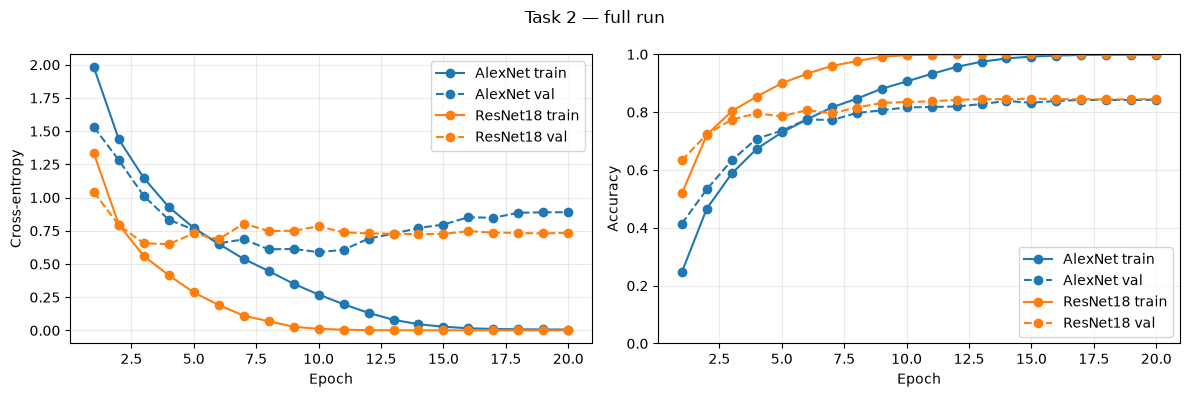

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories.items():
    epochs = [row.epoch for row in history]
    line, = axes[0].plot(epochs, [row.train_loss for row in history], marker="o", label=f"{name} train")
    color = line.get_color()
    axes[0].plot(epochs, [row.val_loss for row in history], "--o", color=color, label=f"{name} val")
    axes[1].plot(epochs, [row.train_accuracy for row in history], "-o", color=color, label=f"{name} train")
    axes[1].plot(epochs, [row.val_accuracy for row in history], "--o", color=color, label=f"{name} val")
axes[0].set_ylabel("Cross-entropy")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.25)
fig.suptitle(f"Task 2 — {'smoke' if alexnet_run.smoke else 'full'} run")
fig.tight_layout()
fig.savefig(task2_output_dir / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()


**Q: Compare the models under a clearly stated compute budget. Report performance, parameter counts, training cost, trained samples and limitations.**

We compare the two baselines on Apple MPS in run `full_20261118T151309Z_9b5cbcb2`, with the shared 20-epoch budget. Each model therefore sees 900,000 training examples across epochs. The table reports the selected validation checkpoint for each network.

| | AlexNet | ResNet-18 |
|---|---:|---:|
| Parameters | 6,976,842 | 11,173,962 |
| Best epoch | 17 | 18 |
| Validation accuracy | 83.84% | 85.74% |
| Validation loss at best | 0.880 | 0.677 |
| Training accuracy at best | 99.78% | 100% |
| Wall-clock time | 4.95 min | 12.94 min |

ResNet reaches a higher validation accuracy (+1.90 percentage points) with about 1.6x as many parameters, at roughly 2.6x the wall time on this machine. Both fits show overfitting: training accuracy is near-perfect while validation stays in the mid-80% range. The comparison uses one seed and one split, and the official test set is still held out for later final evaluation.


## Task 3. Investigate Capacity and Regularization
Investigate how model capacity (n_channels/width, depth, etc.) and regularization influence learning and generalization. Select a feasible set of comparisons and justify what you change and hold fixed. Include L2 regularization, a condition without dropout and two dropout probabilities of your choice. Use learning curves and deterministic training/validation evaluation to distinguish underfitting, overfitting and incomplete optimization.

You may choose either architecture, modify different stages, or use another controlled experimental design.

In [ ]:
TASK3_SMOKE = False  # True = 1 epoch on a tiny ID slice (pipeline check only).

baseline = Run(
    name="alexnet_baseline",
    model="AlexNet",
    group="shared",
    seed=SEED,
    epochs=20,
    batch_size=64,
    lr=0.01,
    momentum=0.9,
    l2=0.0,
    dropout=0.5,
    width_mult=1.0,
    augmentation=False,
)

task3_runs: list[Run] = [
    baseline,
    replace(baseline, name="alexnet_w0.5", group="capacity", width_mult=0.5),
    replace(baseline, name="alexnet_w1.5", group="capacity", width_mult=1.5),
    replace(baseline, name="alexnet_l2_1e-4", group="l2", l2=1e-4),
    replace(baseline, name="alexnet_l2_1e-3", group="l2", l2=1e-3),
    replace(baseline, name="alexnet_dropout_0.0", group="dropout", dropout=0.0),
    replace(baseline, name="alexnet_dropout_0.25", group="dropout", dropout=0.25),
]

task3_group_members: dict[str, list[str]] = {
    "capacity": ["alexnet_w0.5", "alexnet_baseline", "alexnet_w1.5"],
    "l2": ["alexnet_baseline", "alexnet_l2_1e-4", "alexnet_l2_1e-3"],
    "dropout": ["alexnet_dropout_0.0", "alexnet_dropout_0.25", "alexnet_baseline"],
}

if TASK3_SMOKE:
    task3_runs = [run.get_smoke() for run in task3_runs]
    task3_train_ids = train_ids[:512]
    task3_val_ids = val_ids[:256]
else:
    task3_train_ids = train_ids
    task3_val_ids = val_ids

print("Task 3 runs:")
for run in task3_runs:
    print(asdict(run))


In [ ]:
task3_run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
task3_output_dir = Path("outputs") / "task3" / f"{'smoke' if TASK3_SMOKE else 'full'}_{task3_run_id}"
task3_output_dir.mkdir(parents=True, exist_ok=False)

(task3_output_dir / "config.json").write_text(
    json.dumps(
        {
            "runs": [asdict(run) for run in task3_runs],
            "group_members": task3_group_members,
            "normalization": stats,
            "train_size": len(task3_train_ids),
            "validation_size": len(task3_val_ids),
        },
        indent=2,
    ),
    encoding="utf-8",
)
np.savez(task3_output_dir / "split_ids.npz", train_ids=task3_train_ids, val_ids=task3_val_ids)
print("Output directory:", task3_output_dir.resolve())


In [ ]:
task3_histories: dict[str, list[EpochResult]] = {}
task3_summaries: list[RunSummary] = []
for run in task3_runs:
    task3_histories[run.name], summary = train_model(
        run,
        output_dir=task3_output_dir,
        train_ids=task3_train_ids,
        val_ids=task3_val_ids,
    )
    task3_summaries.append(summary)
    comparison_task3 = pd.DataFrame(map(asdict, task3_summaries))
    comparison_task3.to_csv(task3_output_dir / "comparison.csv", index=False)
display(comparison_task3)
if TASK3_SMOKE:
    print("SMOKE CHECK ONLY: set TASK3_SMOKE=False and rerun from the configuration cell for report results.")


In [ ]:
groups = ["capacity", "l2", "dropout"]
fig, axes = plt.subplots(len(groups), 2, figsize=(12, 3.8 * len(groups)), sharex=True)

for row, group in enumerate(groups):
    for name in task3_group_members[group]:
        history = task3_histories[name]
        epochs = [point.epoch for point in history]
        line, = axes[row, 0].plot(
            epochs, [point.train_loss for point in history], marker="o", label=f"{name} train"
        )
        color = line.get_color()
        axes[row, 0].plot(
            epochs, [point.val_loss for point in history], "--o", color=color, label=f"{name} val"
        )
        axes[row, 1].plot(
            epochs, [point.train_accuracy for point in history], "-o", color=color, label=f"{name} train"
        )
        axes[row, 1].plot(
            epochs, [point.val_accuracy for point in history], "--o", color=color, label=f"{name} val"
        )
    axes[row, 0].set_ylabel(f"{group}\ncross-entropy")
    axes[row, 1].set_ylabel(f"{group}\naccuracy")
    axes[row, 1].set_ylim(0, 1)
    for ax in axes[row]:
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

axes[-1, 0].set_xlabel("Epoch")
axes[-1, 1].set_xlabel("Epoch")
fig.suptitle(f"Task 3 - {'smoke' if TASK3_SMOKE else 'full'} runs")
fig.tight_layout()
fig.savefig(task3_output_dir / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
task3_checkpoint_metrics = evaluate_best_checkpoints(task3_output_dir)
display(task3_checkpoint_metrics.round(6))


**Q: What did we change, what did we hold fixed, and what do the curves suggest?**

We use AlexNet with the Task 1 split, seed `2223`, batch size `64`, no augmentation, and a fixed budget of 20 epochs with SGD and cosine learning-rate scheduling. Each experiment changes one factor while keeping the others at the shared baseline: `width_mult=1.0`, `dropout=0.5`, and `l2=0`.

The sweep covers:

- **Capacity:** `width_mult` ∈ {`0.5`, `1.0`, `1.5`}.
- **L2 regularization:** weight decay ∈ {`0`, `1e-4`, `1e-3`}.
- **Dropout:** head dropout ∈ {`0`, `0.25`, `0.5`}.

Results are from Mac MPS run `full_20261119T172504Z_309c288e`. Validation metrics and training accuracy are reported at each run’s best validation checkpoint; wall time covers the full run. The shared baseline is reused across all three groups.

| Run | Parameters | Best epoch | Validation accuracy | Validation loss | Training accuracy at best epoch | Wall time |
|---|---:|---:|---:|---:|---:|---:|
| Baseline | 6.98M | 17 | 83.84% | 0.880 | 99.78% | 4.31 min |
| `width_mult=0.5` | 1.75M | 17 | 82.00% | 0.804 | 98.04% | 2.08 min |
| `width_mult=1.5` | 15.69M | 19 | 84.54% | 0.883 | 99.97% | 7.94 min |
| `l2=1e-4` | 6.98M | 16 | 84.12% | 0.785 | 99.47% | 4.40 min |
| `l2=1e-3` | 6.98M | 18 | 84.24% | 0.580 | 98.16% | 4.19 min |
| `dropout=0` | 6.98M | 15 | 82.78% | 1.209 | 100.00% | 4.08 min |
| `dropout=0.25` | 6.98M | 16 | 83.36% | 0.992 | 99.92% | 4.09 min |

**Capacity.** Halving the width reduces validation accuracy from 83.84% to 82.00% and training accuracy at the best checkpoint from 99.78% to 98.04%, suggesting that reduced capacity limits performance. Increasing the width to `1.5` achieves the highest validation accuracy, 84.54%, but requires about 2.25 times as many parameters and 1.84 times the wall time for a gain of only 0.70 percentage points. All three widths show signs of overfitting after roughly epoch 10, as training loss approaches zero while validation loss rises. Extra capacity therefore provides a modest accuracy gain at a substantial computational cost without resolving overfitting.

**L2 regularization.** Both weight-decay settings improve validation accuracy over the baseline: `1e-4` reaches 84.12%, and `1e-3` reaches 84.24%. The stronger setting also reduces validation loss from 0.880 to 0.580 and keeps it flatter late in training. Its slightly lower training accuracy of 98.16% is consistent with effective regularization, while the high training accuracy indicates that optimization still progresses well within the 20-epoch budget.

**Dropout.** Removing dropout produces the weakest results in the dropout group. Validation loss is already 1.209 at the best checkpoint and rises to approximately 1.27 by epoch 20, alongside a larger gap between training and validation accuracy. With `dropout=0.25`, performance falls between no dropout and the Task 2 default of `0.5`. The baseline achieves the highest validation accuracy in this group, at 83.84%, indicating that head dropout remains useful under this training budget.

**Overall.** Every configuration reduces training loss sharply within 20 epochs, so the dominant issue is overfitting rather than stalled optimization. Among the tested single-factor changes, `l2=1e-3` offers the strongest validation-loss improvement and a modest accuracy gain at approximately the baseline’s wall time. Increasing `width_mult` to `1.5` achieves the highest validation accuracy, but at a much greater computational cost.

## Task 4. Evaluate Robustness
Investigate whether training augmentation improves performance on clean and corrupted images. Choose suitable transformations and parameters, explain how they relate to image changes, and compare models on the same evaluation images. Separate random training views from reproducible evaluation corruptions. Discuss label ambiguity, changed error patterns and cost.

You may start with crop/flip or other corruptions. Develop the method on validation data, and freeze it for final testing.

In [17]:
# Regarding the original model (trained on clean images) we will reuse the checkpoints of previous tasks
checkpoint = torch.load(
    "outputs/task2/full_20261120T105658Z_b3bb1ac1/AlexNet_best.pt",
    map_location="cpu",
    weights_only=True,
)

original_run = Run(**checkpoint["config"])

print("Validation accuracy:", f"{checkpoint['val_accuracy']:.2%}")

Validation accuracy: 84.30%


In [48]:
# Reuse the same training hyperparameters as before

augmented_run = replace(
    original_run,
    name="AlexNet_augmented",
    group="robustness",
    augmentation=True,
)

## WHy this particular augmentation choice

First of all we decided to use the AlexNet because it was the one that showed more overfitting in previous steps of this lab.
This motivates trying to understand whether training augmentation might improve generalization and robustness. 
We compare its existing baseline checkpoint with an AlexNet trained from scratch under the same settings, adding random cropping and horizontal flipping.

We decided to apply two transformations to the training images:

- **Random crop with four pixels of reflection padding:** the image is
  padded and a random crop of 32x32 pixels is selected. 
  This introduces small changes the object position within the image, forcing the model to recognize
  objects without relying on their location in the image.

- **Random horizontal flip with probability 0.5:** the image is mirrored
  left-to-right. CIFAR-10 categories remain unchanged when an
  element faces the opposite direction, so this helps the model to learn to 
  recognize both orientations.

These transformations are applied randomly during training, before
normalization. Validation images remain unchanged. 
Robustness is then measured separately using fixed, reproducible evaluation corruptions shared by both models.

The transformations are deliberately moderate because we thought aggressive cropping might remove important
parts of the elements inside the image and make the label ambiguous.

AugmentedImages as a class is defined before the shared DataLoader for readability.

### Add a mention here to the augmented images definition

In [44]:
## Now it's time to train the model under data augmentation

# Create a separate folder for this experiment.
run_id = (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_"
    + uuid.uuid4().hex[:8]
)

task4_output_dir = Path("outputs") / "task4" / run_id
task4_output_dir.mkdir(parents=True, exist_ok=False)

# maintain the hyperparameters settings and data split.
(task4_output_dir / "config.json").write_text(
    json.dumps(
        {
            "run": asdict(augmented_run),
            "normalization": stats,
        },
        indent=2,
    ),
    encoding="utf-8",
)

np.savez(
    task4_output_dir / "split_ids.npz",
    train_ids=train_ids,
    val_ids=val_ids,
)

# train a new AlexNet with random crops and horizontal flips.
augmented_history, augmented_summary = train_model(
    augmented_run,
    output_dir=task4_output_dir,
    train_ids=train_ids,
    val_ids=val_ids,
)

# save the run and the cost
pd.DataFrame([asdict(augmented_summary)]).to_csv(
    task4_output_dir / "training_comparison.csv",
    index=False,
)

print("Checkpoint:", augmented_summary.checkpoint)
print("Best epoch:", augmented_summary.best_epoch)
print(
    "Best clean validation accuracy:",
    f"{augmented_summary.best_val_accuracy:.2%}",
)
print(
    "Training-run time:",
    f"{augmented_summary.wall_seconds / 60:.2f} minutes",
)

[1/20] AlexNet_augmented:  29%|████████████▎                              | 202/704 [00:07<00:18, 26.64it/s]


KeyboardInterrupt: 

Now we would like to evaluate the ability of the two different models to handle different kind of images (clean or augmented).
Let's first define a class which defines the fixed changes (corruptions) that we will apply to the evaluation images in the different cases 
we will cover

In [47]:
from torchvision.transforms import InterpolationMode


class FixedCorruption:
    def __init__(self, kind="clean", severity=0.0, seed=2223):
        self.kind = kind
        self.severity = severity
        self.seed = seed

    def __call__(self, image, image_id):
        if self.kind == "clean":
            return image

        if self.kind == "noise":
            generator = torch.Generator().manual_seed(
                self.seed + int(image_id)
            )

            noise = torch.randn(
                image.shape,
                generator=generator,
                dtype=image.dtype,
            )

            return (image + self.severity * noise).clamp(0, 1)

        if self.kind == "rotation":
            return TF.rotate(
                image,
                angle=self.severity,
                interpolation=InterpolationMode.BILINEAR,
                expand=False,
                fill=0,
            )

        if self.kind == "blur":
            return TF.gaussian_blur(
                image,
                kernel_size=[5, 5],
                sigma=[self.severity, self.severity],
            )

        raise ValueError(f"Unknown corruption: {self.kind}")


conditions = {
    "clean": FixedCorruption(),
    "noise_0.05": FixedCorruption("noise", 0.05),
    "noise_0.10": FixedCorruption("noise", 0.10),
    "rotation_10": FixedCorruption("rotation", 10),
    "rotation_25": FixedCorruption("rotation", 25),
    "blur_0.5": FixedCorruption("blur", 0.5),
    "blur_1.0": FixedCorruption("blur", 1.0),
}


### Modification to the images we applied

To investigate the abilities of the model, we evaluate the original and augmented AlexNet
on the same validation images under the following list of conditions. 
Each "corruption" is applied separately to the original image, before
normalization. The original class label is retained.

| Condition | Transformation | Purpose |
|---|---|---|
| Clean | No modification | Establish reference performance |
| Noise, σ = 0.05 | Add Gaussian noise with standard deviation 0.05 | Test sensitivity to moderate pixel-level disturbances |
| Noise, σ = 0.10 | Add Gaussian noise with standard deviation 0.10 | Test sensitivity to stronger pixel-level disturbances |
| Rotation, 10° | Rotate counterclockwise by 10 degrees | Test sensitivity to a small change in orientation |
| Rotation, 25° | Rotate counterclockwise by 25 degrees | Test sensitivity to a larger change in orientation |
| Blur, σ = 0.5 | Apply Gaussian blur with standard deviation 0.5 pixels | Test sensitivity to mild loss of fine detail |
| Blur, σ = 1.0 | Apply Gaussian blur with standard deviation 1.0 pixels | Test sensitivity to stronger loss of fine detail |

#### Gaussian noise

Noise is added to image tensors whose pixel values are in the interval [0, 1].
The perturbed values are limited to this range. A larger standard
deviation produces stronger disturbances.

For reproducibility, each image receives a noise pattern generated from
a fixed seed. Both models therefore
receive exactly the same noisy images. 

#### Rotation

Images are rotated using bilinear interpolation while keeping their dimensions. Areas outside the original image are filled with
black, and content near the edges may be cropped. Performance changes reflect orientation changes and boundary effects.

#### Gaussian blur

A 5×5 Gaussian filter smooths the image, reducing sharp edges and fine
texture. A larger standard deviation produces stronger smoothing.

#### Fair comparison and label ambiguity

The validation image IDs and corruption settings are identical for both
models. These fixed evaluation modifications are separate from the random
crops and horizontal flips used during augmented training.

The transformations are intended to preserve the class, but stronger
corruptions can make labels ambiguous. Heavy noise or blur may hide
distinguishing features, while rotation may crop important object parts.

### Validation

Now it's time to the test the model under the different abovementioned conditions.
Let's first restore the model's checkpoints


In [19]:
evaluation_models = {}

checkpoints = {
    "Original": checkpoint,
    "Augmented": torch.load(
        "outputs/task4/20261120T141502Z_dd09daff/AlexNet_augmented_best.pt",
        map_location="cpu",
        weights_only=True,
    ),
}

for name, saved in checkpoints.items():
    model = build_model(Run(**saved["config"]))
    model.load_state_dict(saved["state_dict"])
    model = model.to(device).eval()

    evaluation_models[name] = {
        "model": model,
        "stats": saved["stats"],
    }

# Keep local evaluation results separate from the shared training-run files.
task4_output_dir = Path("results/task4/nov20_checkpoint_evaluation")
task4_output_dir.mkdir(parents=True, exist_ok=True)

Let's define now a class with the different evaluation functions


In [35]:
# helper for synhronization
def synchronize_device():
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


@torch.inference_mode()
def evaluate_corruption(model, normalization_stats, corruption):
    model.eval()
    rows = []

    # no shuffling -> both models receive the same validation images in the same order
    loader = DataLoader(
        RawImages(database, val_ids),
        batch_size=original_run.batch_size,
        shuffle=False,
        num_workers=0,
    )

    for raw, targets, image_ids in loader:
        # apply modifications before normalization.
        changed = torch.stack([
            corruption(image, int(image_id))
            for image, image_id in zip(raw, image_ids)
        ])

        inputs = prepare_inputs(
            changed.to(device),
            normalization_stats,
        )
        logits = model(inputs)

        losses = nn.functional.cross_entropy(
            logits,
            targets.to(device),
            reduction="none",
        )
        predictions = logits.argmax(dim=1).cpu()

        rows.append(pd.DataFrame({
            "image_id": image_ids.numpy(),
            "target": targets.numpy(),
            "prediction": predictions.numpy(),
            "correct": predictions.eq(targets).numpy(),
            "loss": losses.cpu().numpy(),
        }))

    return pd.concat(rows, ignore_index=True)

Now let's run the comparison

In [21]:
prediction_frames = []
evaluation_cost_rows = []

for model_name, saved_model in evaluation_models.items():
    model = saved_model["model"]
    normalization_stats = saved_model["stats"]

    # Warm up before measuring evaluation time.
    with torch.inference_mode():
        dummy = torch.zeros(
            original_run.batch_size, 3, 32, 32,
            device=device,
        )
        for _ in range(3):
            model(prepare_inputs(dummy, normalization_stats))

    synchronize_device()

    for condition_name, corruption in conditions.items():
        synchronize_device()
        start = time.perf_counter()

        predictions = evaluate_corruption(
            model,
            normalization_stats,
            corruption,
        )

        synchronize_device()
        elapsed = time.perf_counter() - start

        predictions["model"] = model_name
        predictions["condition"] = condition_name
        prediction_frames.append(predictions)

        evaluation_cost_rows.append({
            "model": model_name,
            "condition": condition_name,
            "evaluation_seconds": elapsed,
        })

        print(
            f"{model_name:10s} | {condition_name:12s} | "
            f"accuracy: {predictions['correct'].mean():.2%} | "
            f"time: {elapsed:.2f}s"
        )

task4_predictions = pd.concat(
    prediction_frames,
    ignore_index=True,
)
evaluation_costs = pd.DataFrame(evaluation_cost_rows)

Original   | clean        | accuracy: 84.30% | time: 1.81s


Original   | noise_0.05   | accuracy: 78.48% | time: 2.20s


Original   | noise_0.10   | accuracy: 56.16% | time: 2.20s


Original   | rotation_10  | accuracy: 66.48% | time: 4.92s


Original   | rotation_25  | accuracy: 40.14% | time: 5.87s


Original   | blur_0.5     | accuracy: 81.38% | time: 6.38s


... (4 outputs left out)

Augmented  | rotation_10  | accuracy: 74.00% | time: 5.34s


Augmented  | rotation_25  | accuracy: 50.02% | time: 5.47s


Augmented  | blur_0.5     | accuracy: 84.38% | time: 6.79s


Augmented  | blur_1.0     | accuracy: 53.24% | time: 6.21s


Now let's print a table with the obtained results for a further discussion

In [22]:
robustness = (
    task4_predictions
    .groupby(["model", "condition"], as_index=False)
    .agg(
        accuracy=("correct", "mean"),
        loss=("loss", "mean"),
        samples=("correct", "size"),
    )
    .merge(
        evaluation_costs,
        on=["model", "condition"],
        validate="one_to_one",
    )
)

clean_accuracy = (
    robustness.query("condition == 'clean'")
    .set_index("model")["accuracy"]
)

robustness["drop_pp"] = 100 * (
    robustness["model"].map(clean_accuracy) - robustness["accuracy"]
)

accuracy_table = (
    robustness.pivot(
        index="condition", columns="model", values="accuracy"
    )
    .reindex(conditions)
    .mul(100)
)

accuracy_table["augmentation_gain_pp"] = (
    accuracy_table["Augmented"] - accuracy_table["Original"]
)

for filename, table in {
    "validation_predictions": task4_predictions,
    "validation_robustness": robustness,
}.items():
    table.to_csv(task4_output_dir / f"{filename}.csv", index=False)

(task4_output_dir / "corruptions.json").write_text(
    json.dumps(
        {name: vars(corruption) for name, corruption in conditions.items()},
        indent=2,
    ),
    encoding="utf-8",
)

display(accuracy_table.round(2))

model,Augmented,Original,augmentation_gain_pp
condition,,,
clean,87.28,84.30,2.98
noise_0.05,77.10,78.48,-1.38
noise_0.10,46.44,56.16,-9.72
rotation_10,74.00,66.48,7.52
rotation_25,50.02,40.14,9.88
blur_0.5,84.38,81.38,3.00
blur_1.0,53.24,53.58,-0.34


**Q: How is the performance of the model under clean images(the original one)**

Inserting random cropping and horizontal flipping in the training phase of the model improved validation accuracy from **84.30% to 87.28%**, a gain of **2.98 percentage points**. This shows that the model is now more able to generalize and has better capability of predicting the "normal" images.
The augmented model’s higher validation accuracy suggests improved generalization and is consistent with reduced overfitting. However, confirming this requires comparing training and validation performance under the same evaluation conditions. The reduced noise robustness indicates a limitation of the chosen augmentation strategy rather than direct evidence of increased overfitting.

**Q: How is the performance of the model under "corrupted" images**
As it can be seen from the graph above (in the previous cell) the benefits depend heavily on the transformation applied to the validation image.
Augmentation improved accuracy under 10° and 25° rotations by **7.52** and **9.88 percentage points**, respectively, and under mild blur by **3.00 points**. However, it reduced accuracy under Gaussian noise by **1.38 points** at σ = 0.05 and **9.72 points** at σ = 0.10. With strong blur both models produced similar results. Therefore, crop-and-flip augmentation improved robustness to some transformations but did not provide a uniform improvement in any case.

The table above is a local CUDA reevaluation with cuDNN TF32 enabled. Compared with the shared CSV, five predictions have different class labels, but only image 4195 changes correctness. For that image's original 64-image batch, disabling TF32 gives bird and enabling it gives the correct label, deer. This accounts for Original's strong-noise accuracy of 56.16% here versus 56.14% in the shared result. The other four label changes remain errors and do not change aggregate accuracy.

**Q: What are the types of errors included and is there a possible label ambiguity?** 
Rotation changes object orientation and can crop boundary content, blur removes fine detail, and noise obscures visual features(as explained some blocks above). These effects can surely remove information needed to distinguish classes, although specific class confusions require inspecting individual predictions. If we had applied stronger transformations we might also have made the original label ambiguous.

**Q: What was the additional computational cost for the model under augmented reality?** 
The augmented training run took approximately **9.29 minutes**. 
### TODO THE COMPARISON WITH THE ORIGINAL MODEL AS WE USED A DIFFERENT CHECKPOINT AND MACHINE

## Task 5. Analyse Predictions and Adversarial Examples
Combine quantitative evaluation with examples of successful and unsuccessful predictions. Decide which metrics, visualizations and examples best explain the models' behaviour. Generate an adversarial input against a trained model, describe the perturbation, and assess the observed effect. Distinguish deliberately optimized perturbations from random corruption. Define success for the adversarial attacks. Explain class-specific errors, learning curves and representative images alongside the numerical results.

We follow A7 and A8 in `ID2223_Lab_Session_2.ipynb` for the learning curves, predictions, confusion matrices, FGSM attack and inference timing.

We compare the Original AlexNet from the November 20 Task 2 run `full_20261120T105658Z_b3bb1ac1` with Augmented from the Task 4 run `20261120T141502Z_dd09daff`. Both use the same architecture and 20-epoch training budget, with random crops and horizontal flips added for Augmented. Both selected checkpoints are from epoch 20, with validation accuracies of 84.30% for Original and 87.28% for Augmented.

We rebuild the stratified split from Task 1 with seed 2223, which gives 45,000 training images and 5,000 validation images. Each model uses the normalization statistics saved in its own checkpoint. We do not use the official test set here.

To rerun this part without training, start a fresh kernel and run these cells using zero-based numbering:

1. Shared definitions: cells 3-4, 7-11, 14-15, 18-21 and 29-30.
2. Task 4 evaluation: cells 43, 49, 52, 54, 56 and 58.
3. Tasks 5 and 6: cells 61-80, in order.

Do not run cell 28, because it creates a new output folder, and do not run the training cells 32, 38 and 47. If smoke mode was used earlier, rerunning cell 7 restores the full validation split.

Task 4 saves its evaluation results in `results/task4/nov20_checkpoint_evaluation`, and Task 6 reuses them. Tasks 5 and 6 save their results in `results/task5_6/nov20_checkpoints`.

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

checkpoint_paths = {
    "Original": Path("outputs/task2/full_20261120T105658Z_b3bb1ac1/AlexNet_best.pt"),
    "Augmented": Path("outputs/task4/20261120T141502Z_dd09daff/AlexNet_augmented_best.pt"),
}
analysis_dir = Path("results/task5_6/nov20_checkpoints")
analysis_dir.mkdir(parents=True, exist_ok=True)
# Recreate the full Task 1 split, even if the earlier cells were run in smoke mode.
analysis_train_ids, analysis_ids = train_test_split(
    np.arange(len(database)),
    test_size=0.1,
    stratify=labels,
    random_state=2223,
)
analysis_train_ids, analysis_ids = np.sort(analysis_train_ids), np.sort(analysis_ids)
analysis_loader = DataLoader(
    RawImages(database, analysis_ids), batch_size=64, shuffle=False,
)
analysis_models = {}
checkpoint_rows = []
for name, path in checkpoint_paths.items():
    saved = torch.load(path, map_location="cpu", weights_only=True)
    run = Run(**saved["config"])
    model = build_model(run).to(device)
    model.load_state_dict(saved["state_dict"])
    analysis_models[name] = (model.eval(), saved["stats"])
    checkpoint_rows.append({
        "model": name,
        "checkpoint": path.as_posix(),
        "best_epoch": saved["epoch"],
        "epochs": run.epochs,
        "seed": run.seed,
        "augmentation": run.augmentation,
        "parameters": sum(p.numel() for p in model.parameters()),
        "trained_samples": run.epochs * len(analysis_train_ids),
        "saved_val_accuracy": saved["val_accuracy"],
        "saved_val_loss": saved["val_loss"],
    })
checkpoint_info = pd.DataFrame(checkpoint_rows).set_index("model")
checkpoint_info.to_csv(analysis_dir / "checkpoint_info.csv")
np.savez(analysis_dir / "split_ids.npz", train_ids=analysis_train_ids, val_ids=analysis_ids)
display(checkpoint_info)
print("Training / validation images:", len(analysis_train_ids), len(analysis_ids))

,checkpoint,best_epoch,epochs,seed,augmentation,parameters,trained_samples,saved_val_accuracy,saved_val_loss
model,,,,,,,,,
Original,outputs/task2/full_20261120T105658Z_b3bb1ac1/A...,20,20,2223,False,6976842,900000,0.8430,0.889861
Augmented,outputs/task4/20261120T141502Z_dd09daff/AlexNe...,20,20,2223,True,6976842,900000,0.8728,0.373738


Training / validation images: 45000 5000


Original


,precision,recall,f1-score,support
airplane,0.872,0.846,0.859,500.000
automobile,0.928,0.926,0.927,500.000
bird,0.792,0.786,0.789,500.000
cat,0.697,0.712,0.704,500.000
deer,0.827,0.822,0.824,500.000
dog,0.769,0.772,0.770,500.000
frog,0.862,0.850,0.856,500.000
horse,0.862,0.884,0.873,500.000
ship,0.927,0.918,0.923,500.000
truck,0.898,0.914,0.906,500.000


Augmented


,precision,recall,f1-score,support
airplane,0.866,0.894,0.880,500.000
automobile,0.922,0.940,0.931,500.000
bird,0.868,0.826,0.846,500.000
cat,0.789,0.732,0.759,500.000
deer,0.863,0.866,0.864,500.000
dog,0.788,0.808,0.798,500.000
frog,0.877,0.910,0.893,500.000
horse,0.897,0.908,0.903,500.000
ship,0.932,0.930,0.931,500.000
truck,0.923,0.914,0.919,500.000


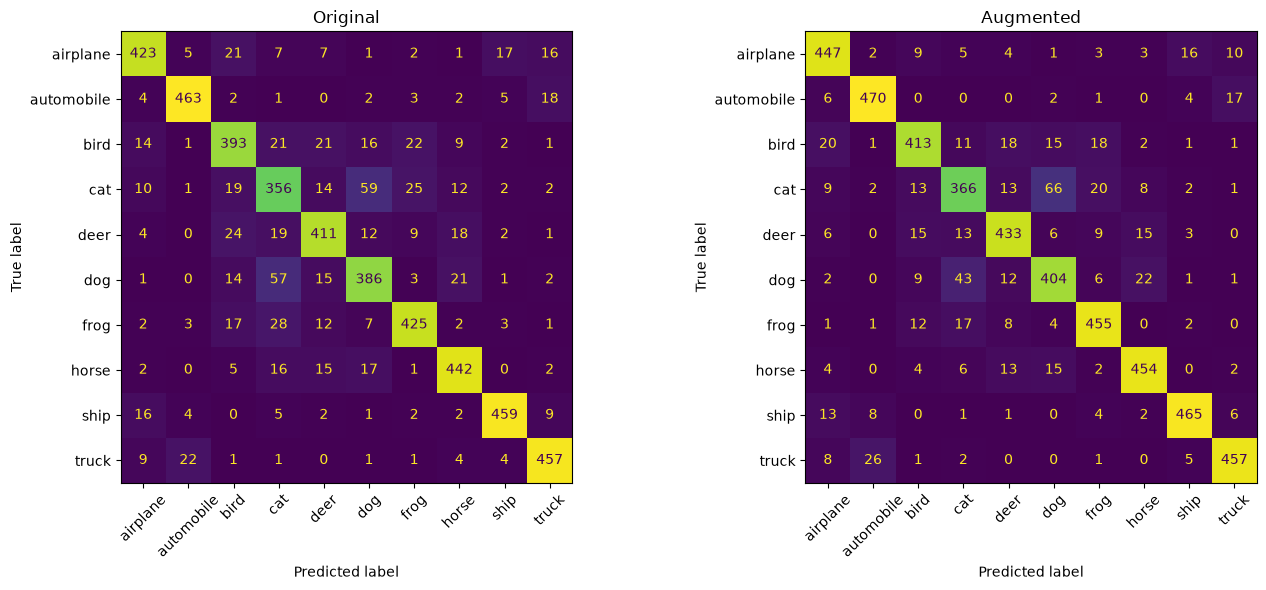

,model,accuracy,loss,macro_f1
0,Original,0.8430,0.8899,0.8431
1,Augmented,0.8728,0.3737,0.8723


In [24]:
@torch.inference_mode()
def collect_predictions(model, normalization_stats, loader):
    model.eval()
    # one row per validation image, so we can pick example images later
    rows = []
    for raw, targets, image_ids in loader:
        logits = model(prepare_inputs(raw.to(device), normalization_stats))
        confidence, prediction = logits.softmax(1).max(1)
        losses = nn.functional.cross_entropy(logits, targets.to(device), reduction="none")
        rows.append(pd.DataFrame({
            "image_id": image_ids.numpy(),
            "target": targets.numpy(),
            "prediction": prediction.cpu().numpy(),
            "confidence": confidence.cpu().numpy(),
            "loss": losses.cpu().numpy(),
        }))
    result = pd.concat(rows, ignore_index=True)
    result["correct"] = result.target == result.prediction
    return result

clean_predictions = {}
metric_rows = []
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, (model, model_stats)) in zip(axes, analysis_models.items()):
    predictions = collect_predictions(model, model_stats, analysis_loader)
    clean_predictions[name] = predictions
    predictions.to_csv(analysis_dir / f"{name}_predictions.csv", index=False)
    report = classification_report(
        predictions.target,
        predictions.prediction,
        target_names=class_names,
        output_dict=True,
    )
    print(name)
    display(pd.DataFrame(report).T.round(3))
    metric_rows.append({
        "model": name,
        "accuracy": predictions.correct.mean(),
        "loss": predictions.loss.mean(),
        "macro_f1": report["macro avg"]["f1-score"],
    })
    ConfusionMatrixDisplay.from_predictions(
        predictions.target,
        predictions.prediction,
        display_labels=class_names,
        ax=ax,
        xticks_rotation=45,
        colorbar=False,
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()
clean_metrics = pd.DataFrame(metric_rows)
display(clean_metrics.round(4))
clean_metrics.to_csv(analysis_dir / "clean_metrics.csv", index=False)

For each model, we look at the four classes with the lowest recall. For each class, the top row shows the first correct prediction and the bottom row shows the first wrong one, in validation order. Picking the images this way makes the selection repeatable. These eight images are only examples and do not cover every error.

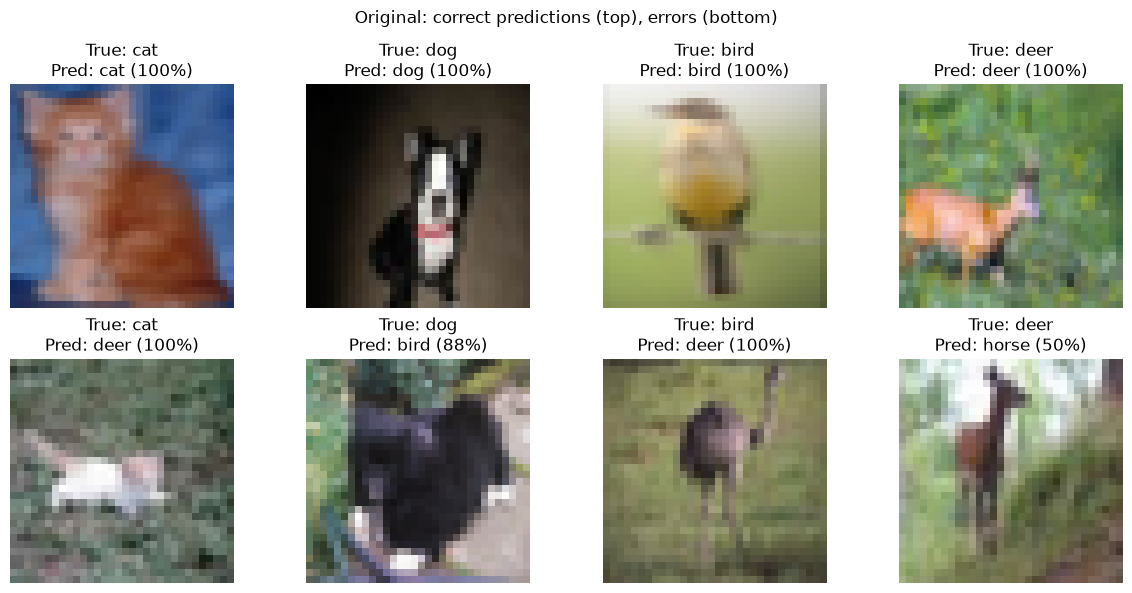

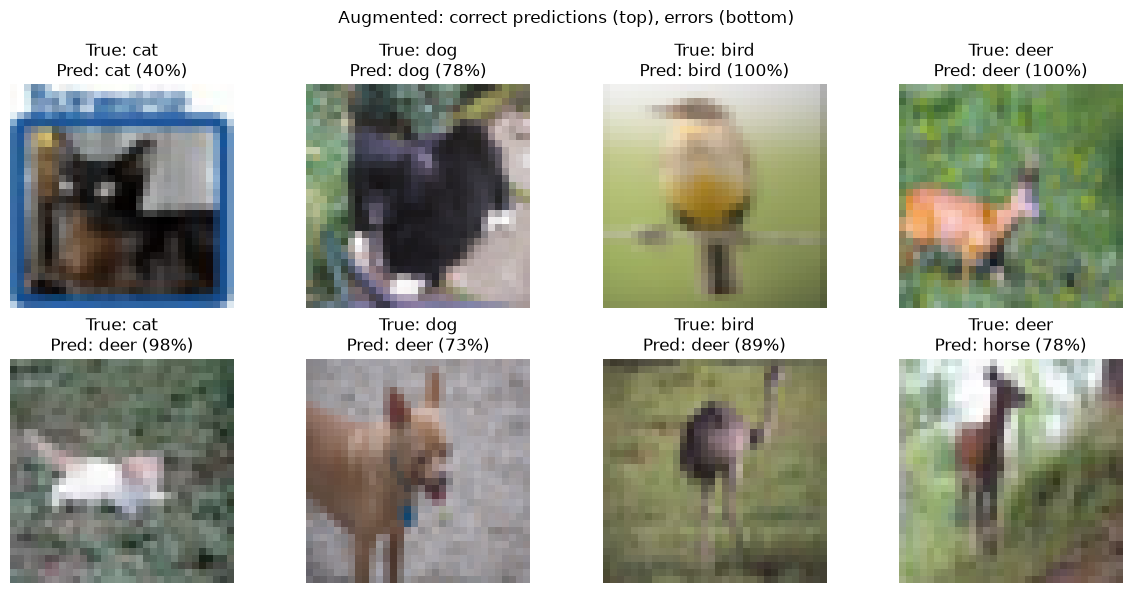

In [25]:
for name, predictions in clean_predictions.items():
    recall = predictions.groupby("target").correct.mean().sort_values()
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for col, target in enumerate(recall.index[:4]):
        for row, correct in enumerate([True, False]):
            example = predictions[
                (predictions.target == target) & (predictions.correct == correct)
            ].iloc[0]
            ax = axes[row, col]
            ax.imshow(database.data[int(example.image_id)])
            predicted = class_names[int(example.prediction)]
            ax.set_title(
                f"True: {class_names[target]}\nPred: {predicted} ({example.confidence:.0%})"
            )
            ax.axis("off")
    fig.suptitle(f"{name}: correct predictions (top), errors (bottom)")
    plt.tight_layout()
    plt.show()

We check the selected checkpoints in two ways. The table evaluates each checkpoint on clean training and validation images in evaluation mode. Dropout is off, so both sets are measured under the same conditions.

The learning curves come from the training logs. Their training metrics were recorded during training, while the weights were still changing and dropout was on. For Augmented, they were also computed on randomly cropped and flipped images. The validation metrics in the curves use evaluation mode and clean images. Because of this, the training numbers in the table and in the curves are not measured under the same conditions.

In [26]:
# clean training images (no crop/flip), so train and validation use the same conditions
clean_train_loader = DataLoader(
    RawImages(database, analysis_train_ids), batch_size=64, shuffle=False,
)
diagnostic_rows = []
for name, (model, model_stats) in analysis_models.items():
    training = evaluate(model, clean_train_loader, model_stats)
    validation = clean_metrics.set_index("model").loc[name]
    diagnostic_rows.append({
        "model": name,
        "best_epoch": checkpoint_info.loc[name, "best_epoch"],
        "train_loss": training.loss,
        "val_loss": validation.loss,
        "train_accuracy": training.accuracy,
        "val_accuracy": validation.accuracy,
        "gap_pp": 100 * (training.accuracy - validation.accuracy),
    })
diagnostics = pd.DataFrame(diagnostic_rows).set_index("model")
display(diagnostics.round(4))
diagnostics.to_csv(analysis_dir / "checkpoint_diagnostics.csv")

,best_epoch,train_loss,val_loss,train_accuracy,val_accuracy,gap_pp
model,,,,,,
Original,20,0.0020,0.8899,0.9998,0.8430,15.6822
Augmented,20,0.2138,0.3737,0.9267,0.8728,5.3867


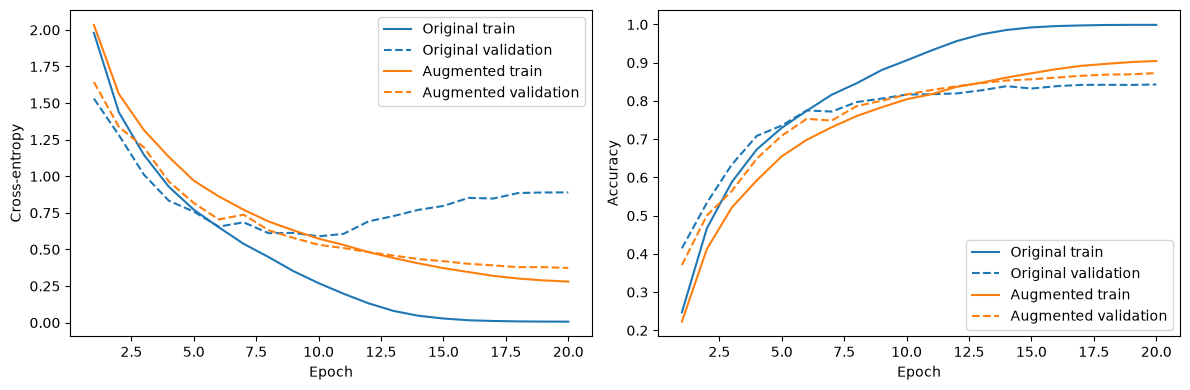

In [27]:
history_paths = {
    "Original": Path("outputs/task2/full_20261120T105658Z_b3bb1ac1/AlexNet_history.csv"),
    "Augmented": Path("outputs/task4/20261120T141502Z_dd09daff/AlexNet_augmented_history.csv"),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (name, history_path), color in zip(history_paths.items(), ["tab:blue", "tab:orange"]):
    history = pd.read_csv(history_path)
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(
            history.epoch, history[f"train_{metric}"],
            color=color, linestyle="-", label=f"{name} train",
        )
        ax.plot(
            history.epoch, history[f"val_{metric}"],
            color=color, linestyle="--", label=f"{name} validation",
        )
for ax, ylabel in zip(axes, ["Cross-entropy", "Accuracy"]):
    ax.set(xlabel="Epoch", ylabel=ylabel)
    ax.legend()
plt.tight_layout()
plt.show()

FGSM takes one step in the direction of the sign of the gradient of the cross-entropy loss with respect to the raw pixels. As in classroom A8, we fix `epsilon = 4/255` before running the attack. Each pixel can change by at most epsilon, and the result is clipped to [0, 1]. The normalization step stays inside the gradient computation.

We attack the first 256 validation images, and each model is attacked with its own gradients. We count an attack as successful when a correct clean prediction becomes wrong. This means the success rate only uses images that the model first classified correctly.

As a control, we also add random signs with the same epsilon and clipping. Both models get the same random perturbations, and these do not use any gradient.

In [28]:
# FGSM as in A8: gradient w.r.t. the raw pixels, with normalization inside the graph
def fgsm(model, raw, targets, normalization_stats, epsilon):
    model.eval()
    attack_input = raw.detach().clone().requires_grad_(True)
    logits = model(prepare_inputs(attack_input, normalization_stats))
    loss = nn.functional.cross_entropy(logits, targets)
    (gradient,) = torch.autograd.grad(loss, attack_input)
    return (attack_input + epsilon * gradient.sign()).clamp(0, 1).detach()

epsilon = 4 / 255
attack_loader = DataLoader(
    RawImages(database, analysis_ids[:256]), batch_size=64, shuffle=False,
)
attack_rows = []
attack_examples = {}
attack_max_linf = {}
for name, (model, model_stats) in analysis_models.items():
    # reset the generator for each model, so both models get the same random signs
    generator = torch.Generator().manual_seed(2223)
    attack_max_linf[name] = 0.0
    for raw, targets, image_ids in attack_loader:
        signs = 2 * torch.randint(0, 2, raw.shape, generator=generator) - 1
        random_input = (raw + epsilon * signs).clamp(0, 1).to(device)
        raw, targets = raw.to(device), targets.to(device)
        adversarial = fgsm(model, raw, targets, model_stats, epsilon)
        attack_max_linf[name] = max(
            attack_max_linf[name], (adversarial - raw).abs().max().item(),
        )
        with torch.inference_mode():
            clean = model(prepare_inputs(raw, model_stats)).argmax(1)
            random_pred = model(prepare_inputs(random_input, model_stats)).argmax(1)
            attack_pred = model(prepare_inputs(adversarial, model_stats)).argmax(1)
        # success: correct before the attack and wrong after it
        success = (clean == targets) & (attack_pred != targets)
        attack_rows.append(pd.DataFrame({
            "model": name,
            "image_id": image_ids.numpy(),
            "target": targets.cpu().numpy(),
            "clean_prediction": clean.cpu().numpy(),
            "random_prediction": random_pred.cpu().numpy(),
            "fgsm_prediction": attack_pred.cpu().numpy(),
        }))
        if name not in attack_examples and success.any():
            i = int(success.nonzero()[0])
            attack_examples[name] = (
                raw[i].cpu(),
                random_input[i].cpu(),
                adversarial[i].cpu(),
                int(targets[i]),
                int(clean[i]),
                int(random_pred[i]),
                int(attack_pred[i]),
            )

attack_details = pd.concat(attack_rows, ignore_index=True)
attack_details.to_csv(analysis_dir / "attack_predictions.csv", index=False)

Next, we summarize clean accuracy, accuracy with random signs and FGSM success on the 256 images.

In [29]:
attack_summary_rows = []
for name, rows in attack_details.groupby("model", sort=False):
    initially_correct = rows.clean_prediction == rows.target
    attack_summary_rows.append({
        "model": name,
        "images": len(rows),
        "initially_correct": int(initially_correct.sum()),
        "clean_accuracy": initially_correct.mean(),
        "random_accuracy": (rows.random_prediction == rows.target).mean(),
        "fgsm_accuracy": (rows.fgsm_prediction == rows.target).mean(),
        "attack_success_rate": (
            rows.loc[initially_correct, "fgsm_prediction"]
            != rows.loc[initially_correct, "target"]
        ).mean(),
        "max_linf": attack_max_linf[name],
    })
attack_summary = pd.DataFrame(attack_summary_rows)
display(attack_summary.round(4))
attack_summary.to_csv(analysis_dir / "attack_summary.csv", index=False)

,model,images,initially_correct,clean_accuracy,random_accuracy,fgsm_accuracy,attack_success_rate,max_linf
0,Original,256,228,0.8906,0.8828,0.2656,0.7018,0.0157
1,Augmented,256,233,0.9102,0.9102,0.2188,0.7597,0.0157


Below is the first successful adversarial example for each model. The last panel shows the perturbation, amplified so that it is visible.

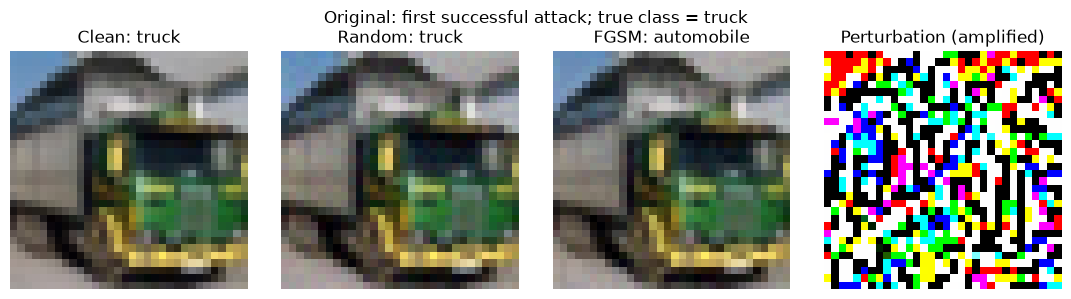

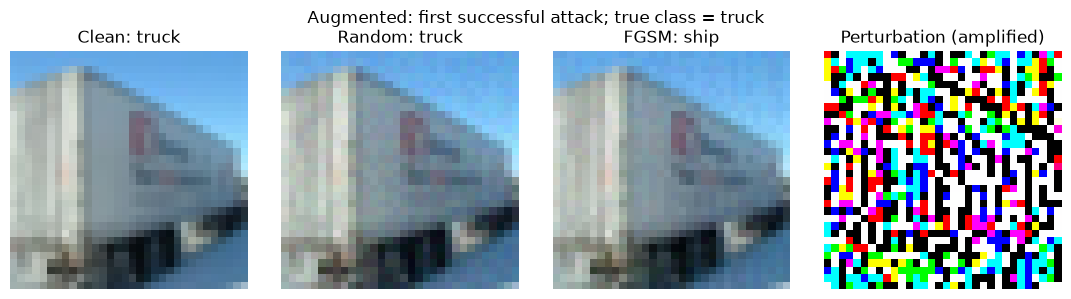

In [30]:
for name, example in attack_examples.items():
    raw, random_input, adversarial, target, clean, random_pred, attack_pred = example
    fig, axes = plt.subplots(1, 4, figsize=(11, 3))
    images = [raw, random_input, adversarial, 0.5 + (adversarial - raw) / (2 * epsilon)]
    titles = [f"Clean: {class_names[clean]}", f"Random: {class_names[random_pred]}",
              f"FGSM: {class_names[attack_pred]}", "Perturbation (amplified)"]
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image.permute(1, 2, 0).clamp(0, 1))
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(f"{name}: first successful attack; true class = {class_names[target]}")
    plt.tight_layout()
    plt.show()

**Q: What do the predictions show?**

Augmentation raises validation accuracy from 84.30% to 87.28%, and the cross-entropy loss drops from 0.890 to 0.374. Cat is still the hardest class, although its recall rises from 71.2% to 73.2%. Cat/dog confusions fall from 116 to 109 in total. However, cat-to-dog errors increase from 59 to 66. Frog improves more, with recall going from 85.0% to 91.0%.

Original makes confident mistakes, such as labeling cat image 39 as a deer with almost 100% confidence. Original's clean training loss is only 0.002, so the model fits the training images almost perfectly. Cross-entropy penalizes confident errors heavily, so these mistakes raise validation loss.

**Q: What do the training diagnostics tell us?**

For Original, validation loss reaches its minimum of 0.590 at epoch 10. After that it rises to 0.890 at epoch 20. In the same period, validation accuracy still improves from 81.66% to 84.30%, and training loss keeps falling. This pattern fits overfitting: the model becomes more confident, also on its mistakes. Because we select checkpoints by accuracy, we keep epoch 20. Among epochs 10-20, this epoch has the highest validation loss.

For Augmented, validation loss is still going down at the end, from 0.420 at epoch 15 to 0.374 at epoch 20. Validation accuracy is also still rising. The curve has not clearly flattened within 20 epochs, so longer training might help.

Clean training accuracy is 99.98% for Original and 92.67% for Augmented. The train/validation gap shrinks from 15.68 to 5.39 percentage points, which suggests that augmentation reduces overfitting.

The history reports 90.44% training accuracy for Augmented at epoch 20, while the table reports 92.67%. They use different conditions and are not directly comparable, as explained above the table.

**Q: Did the attack work?**

On the fixed 256-image subset, FGSM lowers Original's accuracy from 89.06% to 26.56%. Augmented drops from 91.02% to 21.88%. FGSM turns 160 of 228 correct Original predictions into errors, which is a success rate of 70.18%. For Augmented, it is 177 of 233, or 75.97%. Random signs of the same size have almost no effect: accuracy stays at 88.28% and 91.02%.

The first 256 validation images are not a stratified sample: Original gets 89.06% on them, compared with 84.30% on the full validation set. We therefore compare attack results within this subset.

In Task 4, Gaussian noise with a per-channel standard deviation of 0.05, about 13/255, lowers Original's full-validation accuracy by 5.82 points. FGSM, limited to 4/255, cuts subset accuracy from 89.06% to 26.56%. However, the noise sizes and image sets are different, so the random-sign control is the direct comparison.

Both examples show a truck, but they are different images, because we take each model's first successful attack. Original changes its answer from truck to automobile, and Augmented changes it from truck to ship. In this test, crop-and-flip training improved clean accuracy but did not improve resistance to FGSM, a one-step, white-box attack.

## Task 6. Benchmark and Discuss the Tradeoffs
Measure the costs that matter for your intended use and relate them to accuracy, robustness and the compute budget. Choose and describe an inference timing, device, precision and batch size. Discuss how training duration, randomness and hardware constrain the conclusions, and recommend a model or configuration using your measured evidence.

We time Original and Augmented on the same local GPU, following classroom A8. Inputs are normalized and moved to the GPU before timing starts. The models run in evaluation mode with float32 tensors, and the TF32 backend settings are saved with the results. Before each trial, we run five warm-up forward passes. We synchronize the GPU before and after the timer.

For batch sizes 1 and 64, we run six trials of 20 forward passes each, and we alternate which model goes first. The table shows the median and the interquartile range of the mean time per batch. The timing does not include loading images, moving data, preprocessing or computing metrics. Random crops and flips are only used in training, so they are not part of this benchmark.

The robustness numbers come from Task 4's `accuracy_table`. It reports accuracy in percent on the same 5,000 validation images. The full results are in `results/task4/nov20_checkpoint_evaluation/validation_robustness.csv`.

The training-cost table uses the November 20 Task 2 logs and the Task 4 training log. The two AlexNet runs were trained on the same machine. For ResNet18, we only have the logged training time and validation accuracy. Its November 20 checkpoint is not available here, so we could not measure its inference time or robustness.

In [31]:
# same timing loop as A8: warm up, synchronize, then average 20 forward passes
@torch.inference_mode()
def time_inference(model, inputs):
    model.eval()
    for _ in range(5):
        model(inputs)
    synchronize_device()
    start = time.perf_counter()
    for _ in range(20):
        model(inputs)
    synchronize_device()
    return 1000 * (time.perf_counter() - start) / 20

timing_rows = []
raw_batch = next(iter(analysis_loader))[0].to(device)
for batch_size in [1, 64]:
    prepared = {
        name: prepare_inputs(raw_batch[:batch_size], model_stats)
        for name, (_, model_stats) in analysis_models.items()
    }
    for trial in range(6):
        # Alternate which model runs first to reduce measurement-order effects.
        names = list(analysis_models)
        if trial % 2:
            names.reverse()
        for name in names:
            model = analysis_models[name][0]
            batch_ms = time_inference(model, prepared[name])
            timing_rows.append({
                "model": name,
                "batch_size": batch_size,
                "trial": trial + 1,
                "batch_ms": batch_ms,
            })
timing_trials = pd.DataFrame(timing_rows)
timing_trials.to_csv(analysis_dir / "timing_trials.csv", index=False)
timings = (
    timing_trials.groupby(["model", "batch_size"]).batch_ms
    .agg(
        median_ms="median",
        q25_ms=lambda x: x.quantile(.25),
        q75_ms=lambda x: x.quantile(.75),
    )
    .reset_index()
)
timings["ms_per_image"] = timings.median_ms / timings.batch_size
timings["images_per_second"] = 1000 * timings.batch_size / timings.median_ms
display(timings.round(3))
timings.to_csv(analysis_dir / "inference_timing.csv", index=False)
environment = {
    "device": str(device),
    "device_name": torch.cuda.get_device_name(0) if device.type == "cuda" else str(device),
    "torch": str(torch.__version__),
    "cudnn_tf32": torch.backends.cudnn.allow_tf32,
    "cuda_matmul_tf32": torch.backends.cuda.matmul.allow_tf32,
}
(analysis_dir / "environment.json").write_text(json.dumps(environment, indent=2))
print(environment)

,model,batch_size,median_ms,q25_ms,q75_ms,ms_per_image,images_per_second
0,Augmented,1,2.707,2.452,2.909,2.707,369.458
1,Augmented,64,4.840,4.780,4.967,0.076,13222.615
2,Original,1,2.604,2.569,2.814,2.604,384.084
3,Original,64,4.783,4.772,4.962,0.075,13381.507


{'device': 'cuda', 'device_name': 'NVIDIA GeForce RTX 3050 Ti Laptop GPU', 'torch': '2.7.1+cu128', 'cudnn_tf32': True, 'cuda_matmul_tf32': False}


In [32]:
display(accuracy_table.round(2))

costs = checkpoint_info[["parameters", "epochs", "trained_samples"]].join(
    clean_metrics.set_index("model")
)
costs["checkpoint_mib"] = [
    checkpoint_paths[name].stat().st_size / 1024**2 for name in costs.index
]
display(costs.round(4))
costs.to_csv(analysis_dir / "model_comparison.csv")

# training times come from the logs written by train_model in Tasks 2 and 4
training_cost = pd.concat([
    pd.read_csv("outputs/task2/full_20261120T105658Z_b3bb1ac1/comparison.csv"),
    pd.read_csv("outputs/task4/20261120T141502Z_dd09daff/training_comparison.csv"),
]).set_index("name").loc[["AlexNet", "AlexNet_augmented", "ResNet18"]]
training_cost.index = pd.Index(
    ["AlexNet (Original)", "AlexNet (Augmented)", "ResNet18"], name="model",
)
training_cost["wall_minutes"] = training_cost.wall_seconds / 60
training_cost = training_cost[["parameters", "best_epoch", "best_val_accuracy", "wall_minutes"]]
display(training_cost.round(4))
training_cost.to_csv(analysis_dir / "training_cost.csv")

model,Augmented,Original,augmentation_gain_pp
condition,,,
clean,87.28,84.30,2.98
noise_0.05,77.10,78.48,-1.38
noise_0.10,46.44,56.16,-9.72
rotation_10,74.00,66.48,7.52
rotation_25,50.02,40.14,9.88
blur_0.5,84.38,81.38,3.00
blur_1.0,53.24,53.58,-0.34


,parameters,epochs,trained_samples,accuracy,loss,macro_f1,checkpoint_mib
model,,,,,,,
Original,6976842,20,900000,0.8430,0.8899,0.8431,26.6206
Augmented,6976842,20,900000,0.8728,0.3737,0.8723,26.6209


,parameters,best_epoch,best_val_accuracy,wall_minutes
model,,,,
AlexNet (Original),6976842,20,0.8430,9.0452
AlexNet (Augmented),6976842,20,0.8728,9.2893
ResNet18,11173962,15,0.8470,33.5239


**Q: Which model would you choose under your available computational budget, and why?**

With our 20-epoch budget, we would choose AlexNet with crop-and-flip augmentation, as long as the inputs are mostly clean or rotated. It reaches 87.28% validation accuracy with 6,976,842 parameters. Original AlexNet reaches 84.30%. The November 20 ResNet18 reaches 84.70% with 11,173,962 parameters. ResNet takes 33.52 minutes versus 9.05 for Original, about 3.7 times as long, for a 0.40-point accuracy gain. ResNet was trained without augmentation, so the comparison with Augmented is not fully fair.

The two AlexNet models have the same architecture, and both checkpoints are about 26.62 MiB. At batch size 1, Original takes 2.60 ms and Augmented takes 2.71 ms. At batch size 64, they take 4.78 and 4.84 ms per batch. Inference times were similar in these trials, and their interquartile ranges overlapped. Batch size 64 gives much higher throughput. These times do not include loading or preprocessing.

**Q: Which changes improve accuracy or robustness at an acceptable cost?**

Both AlexNet runs used the same machine, 20 epochs and batch size 64, processing 900,000 training examples each. Original took 9.05 minutes and Augmented took 9.29 minutes. In these runs, augmentation added 14.65 seconds, about 2.7%, and improved clean validation accuracy by 2.98 percentage points. With only one run of each model, we cannot tell how consistent this time difference is.

Augmented handles rotation better: at 25 degrees it reaches 50.02%, compared with 40.14% for Original. Strong Gaussian noise (sigma 0.10) shows the opposite. Augmented drops to 46.44%, while Original keeps 56.16%. Under strong blur the two models are almost equal (53.24% and 53.58%). These numbers come from our Task 4 evaluation. If we expect noisy inputs, Original is the better choice. The FGSM results also show that crop-and-flip training does not protect against every kind of perturbation.

**Q: Which conclusions are sensitive to the training duration, random seed, or hardware?**

Augmented's validation loss is still going down at epoch 20, while Original's starts rising after epoch 10. ResNet reaches 84.70% at epoch 15 and ends at 84.46%, so its last five epochs did not help in this run. Augmented seems to have the most room left to improve, so a longer budget could change the ranking.

The inference times were measured on an RTX 3050 Ti Laptop GPU, using float32 tensors with cuDNN TF32 convolutions enabled. GPU load and the order of measurements affect latency, which is why we alternate the model order across the six trials. All experiments use one seed and one data split, so we cannot say how much the results vary between seeds.

**Q: What further experiment would provide the most useful evidence?**

We would add mild noise augmentation to the crop-and-flip AlexNet, using the same training budget. Then we could check whether noise accuracy improves without losing clean accuracy. Training ResNet18 with the same crop-and-flip augmentation would also make the architecture comparison fairer.

## Challenge 1. Model Compression
Investigate whether a trained model can be represented by a smaller or faster model without an unacceptable loss in performance. Choose a method, define what efficiency and acceptable accuracy change mean for your use case, and compare the result with an appropriate reference under a consistent protocol. Report compression or fine-tuning cost as well as deployment cost. A smaller parameter count, sparse mask or smaller file does not automatically imply faster inference.

In [90]:
# code

## Challenge 2. Generalization Beyond the Development Conditions
Investigate whether your model generalizes to an unseen corruption family or a different, suitably labelled image domain. Choose a meaningful shift, explain its relationship to development data, and decide how to measure success. Discuss your findings.

In [91]:
# code

## References
- [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html)
- [AlexNet original paper](https://papers.nips.cc/paper/4824-imagenet-classification-with-deep-convolutional-neural-networks)
- [ResNet original paper](https://arxiv.org/abs/1512.03385)
- [PyTorch Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) and [LocalResponseNorm](https://docs.pytorch.org/docs/stable/generated/torch.nn.LocalResponseNorm.html)
- [FGSM background](https://docs.pytorch.org/tutorials/beginner/fgsm_tutorial.html)